In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
os.environ['KERAS_BACKEND'] = 'torch'    # has to be set before keras is imported

import keras
from keras import layers, regularizers
from keras.layers import Activation, BatchNormalization, Concatenate, Conv2D, Conv2DTranspose, Input, Rescaling, Dense, MaxPooling2D, Resizing
from keras.datasets import mnist
from keras.models import Model

# Set the seeds for reproducibility
from numpy.random import seed
from tensorflow.random import set_seed
seed_value = 1234578790
seed(seed_value)
set_seed(seed_value)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')

if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

    print("GPU memory growth enabled")
else:
    print("No GPU detected")

GPU memory growth enabled


In [ ]:
print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices('GPU')

print("Available GPUs:", gpus)
print("Number of GPUs:", len(gpus))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Number of GPUs: 1


In [ ]:
import math
def preprocess(array):
    array = array.astype("float32") / 255.0
    array = cv2.resize(array, (192, 72))
    return array

def noise(array):
    noise_factor = 0.4
    noisy_array = array + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=array.shape)
    return np.clip(noisy_array, 0.0, 1.0)

degtorad = 0.01745329252
radtodeg = 1/degtorad;

# returns a list of lines
def rand_lines(w,h,a,l,nrs):
    lines=[]
    for i in range(nrs):
        # randomize starting and ending points for 2D lines
        sx = random.randint(0,w-1)
        sy = random.randint(0,h-1)

        le = random.randint(1,l)
        ang = a + random.randint(0,10)
        ex = sx + int(le * math.sin(ang * degtorad))
        ey = sy + int(le * math.cos(ang * degtorad))
        # move the endpoints inside the image frame
        if ex<0: ex = 0
        if ex>w-1: ex=w-1
        if ey<0: ey = 0
        if ey>w-1: ey=h-1
        # add line to list
        lines.append({'sx':sx,'sy':sy,'ex':ex,'ey':ey})
    return lines

def add_rain(img, angle, drop_length, drop_thickness, drop_nrs, blur=4, intensity = 100):
    # create placehplder for rain
    rain=np.zeros((img.shape[0],img.shape[1],img.shape[2]),dtype='uint16')
    # generate random lines
    lines=rand_lines(rain.shape[1],rain.shape[0],angle,drop_length,drop_nrs)
    # draw lines to the image
    for l in lines:
        cv2.line(rain,(l['sx'],l['sy']),(l['ex'],l['ey']),(intensity,intensity,intensity),drop_thickness)
    # add blur to the lines
    rain = cv2.blur(rain,(blur,blur))
    return np.clip(img + rain, 0.0, 1.0)

def display(data_generator, batch_size):
    for array1, array2 in data_generator:
        n = min(4, len(array1))
        indices = np.random.choice(len(array1), size=n, replace=False)

        images1 = array1[indices]
        images2 = array2[indices]

        plt.figure(figsize=(16, 6))

        for i, (image1, image2) in enumerate(zip(images1, images2)):
            ax = plt.subplot(2, n, i + 1)
            plt.imshow(image1)
            ax.axis('off')

            ax = plt.subplot(2, n, i + 1 + n)
            plt.imshow(image2)
            ax.axis('off')

        plt.tight_layout()
        plt.show()

        break

In [ ]:
import glob
import random
#https://zenodo.org/records/13342103
#Synthetic Ukrainian license plate dataset for the paper "License plate images generation with diffusion models" (presented at PAIS 2024)
def load_data(images_path, batch_size, training=True):
    img_files = glob.glob(os.path.join(images_path, '*.png'))
    while True:
      if training:
        random.shuffle(img_files)
      #print(len(img_files))
      for i in range(0, len(img_files), batch_size):
        batch_files = img_files[i:i + batch_size]
        images = []
        noisy_images = []

        for img_path in batch_files:
          image = cv2.imread(img_path)
          if image is None:
            raise ValueError(f"Cannot read image: {img_path}")
          image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
          image = preprocess(image)
          #noisy_image = noise(image)
          random_angle = random.randint(30, 150)
          random_drop_len = random.randint(4, 15)
          noisy_image = add_rain(image, random_angle, random_drop_len, 1, 100, blur=4, intensity = 100)
          images.append(image)
          noisy_images.append(noisy_image)
        yield (np.asarray(noisy_images, dtype=np.float32), np.asarray(images, dtype=np.float32))

TRAIN_IMG_PATH = '/content/drive/MyDrive/Colab Notebooks/train/images'#'./data/train/images'
VALIDATION_IMG_PATH = '/content/drive/MyDrive/Colab Notebooks/valid/images'#'./data/valid/images'
BATCH_SIZE = 16

train_generator = load_data(TRAIN_IMG_PATH, BATCH_SIZE, training=True)
validation_generator = load_data(VALIDATION_IMG_PATH, BATCH_SIZE, training=False)

display(train_generator, BATCH_SIZE)

In [ ]:
train_batch = next(train_generator)
validation_batch = next(validation_generator)

print("Training:")
print("Input:", train_batch[0].shape)
print("Target:", train_batch[1].shape)

print("\nValidation:")
print("Input:", validation_batch[0].shape)
print("Target:", validation_batch[1].shape)

Training:
Input: (16, 72, 192, 3)
Target: (16, 72, 192, 3)

Validation:
Input: (16, 72, 192, 3)
Target: (16, 72, 192, 3)


In [ ]:
inputs = layers.Input(shape=(72, 192, 3))

# Encoder
x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(inputs)
x = layers.MaxPooling2D((2, 2), padding="same")(x)
x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2), padding="same")(x)

# Decoder
x = layers.Conv2DTranspose(32, (4, 4), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2DTranspose(32, (4, 4), strides=2, activation="relu", padding="same")(x)
#Try layers.UpSampling2D((2, 2)) #This must separate spatial enlargement from feature extraction
outputs = layers.Conv2D(3, (3, 3), activation="sigmoid", padding="same")(x)

autoencoder = Model(inputs, outputs)
#Accuracy is not a useful metric for continuous-valued image reconstruction. For example, predicting a pixel value of 0.51 instead of 0.50 is a small error, but accuracy does not meaningfully describe that error
#Try next use mse+ssim
autoencoder.compile(optimizer='adam', loss='mse', metrics=[keras.metrics.MeanAbsoluteError(name="mae")])
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 72, 192, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 72, 192, 32)    │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 36, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 36, 96, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 18, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 36, 96, 32)     │        16,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 72, 192, 32)    │        16,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 72, 192, 3)     │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,843 (171.26 KB)

 Trainable params: 43,843 (171.26 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import math
train_size = len(glob.glob(os.path.join(TRAIN_IMG_PATH, '*.png')))

validation_size = len(glob.glob(os.path.join(VALIDATION_IMG_PATH, '*.png')))

EPOCHS = 25
STEPS_PER_EPOCH = math.ceil(train_size / BATCH_SIZE)
VALIDATION_STEPS = math.ceil(validation_size / BATCH_SIZE)
print("STEPS_PER_EPOCH: ", STEPS_PER_EPOCH)
print("VALIDATION_STEPS: ", VALIDATION_STEPS)

checkpoint = keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True, verbose=1)
earlyStop = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience = 7, restore_best_weights=True, verbose=1)

history = autoencoder.fit(train_generator, steps_per_epoch=STEPS_PER_EPOCH, epochs=EPOCHS,
                          validation_data=validation_generator, validation_steps=VALIDATION_STEPS,
                          callbacks=[checkpoint, earlyStop], verbose=2)

STEPS_PER_EPOCH:  500
VALIDATION_STEPS:  63
Epoch 1/25

Epoch 1: val_loss improved from None to 0.00752, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
500/500 - 223s - 445ms/step - loss: 0.0156 - mae: 0.0899 - val_loss: 0.0075 - val_mae: 0.0618
Epoch 2/25

Epoch 2: val_loss improved from 0.00752 to 0.00551, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
500/500 - 57s - 114ms/step - loss: 0.0066 - mae: 0.0573 - val_loss: 0.0055 - val_mae: 0.0518
Epoch 3/25

Epoch 3: val_loss improved from 0.00551 to 0.00447, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
500/500 - 56s - 112ms/step - loss: 0.0051 - mae: 0.0496 - val_loss: 0.0045 - val_mae: 0.0457
Epoch 4/25

Epoch 4: val_loss did not improve from 0.00447
500/500 - 56s - 113ms/step - loss: 0.0042 - mae: 0.0450 - val_loss: 0.0048 - val_mae: 0.0488
Epoch 5/25

Epoch 5: val_loss improved from 0.00447 to 0.00372, saving model to 

Train mae      0.028446905314922333
Validation mae 0.028443625196814537


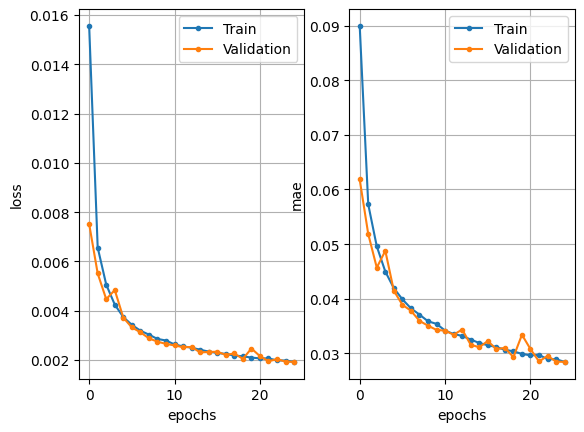

In [ ]:
def plot_history(history):
    h = history.history
    epochs = range(len(h['loss']))

    plt.subplot(121), plt.plot(epochs, h['loss'], '.-', epochs, h['val_loss'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('loss')
    plt.legend(['Train', 'Validation'])
    plt.subplot(122), plt.plot(epochs, h['mae'], '.-',
                               epochs, h['val_mae'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('mae')
    plt.legend(['Train', 'Validation'])

    print('Train mae     ', h['mae'][-1])
    print('Validation mae', h['val_mae'][-1])

plot_history(history)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Noisy images: (16, 72, 192, 3)
Predictions: (16, 72, 192, 3)
Clean images: (16, 72, 192, 3)


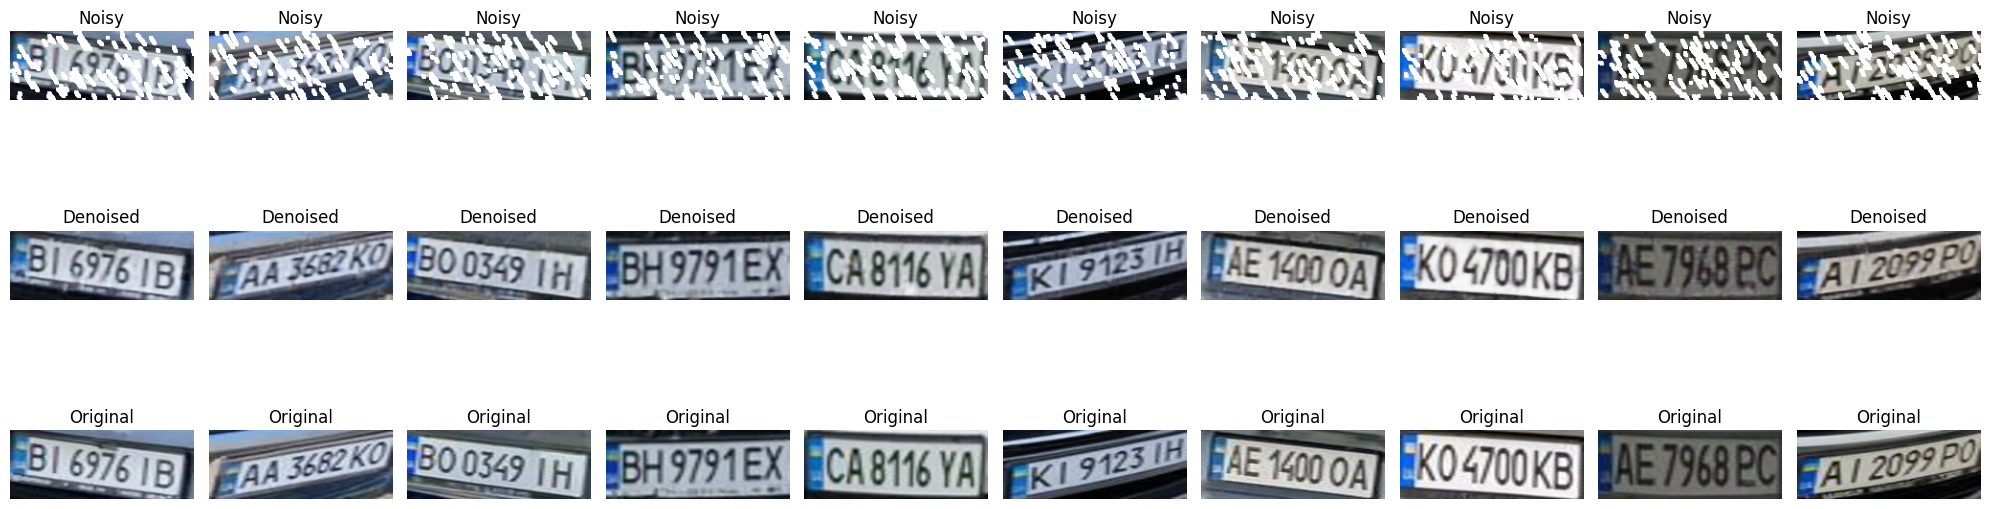

In [ ]:

def display_predictions(noisy_images, predictions, clean_images, n=10):
    n = min(n, len(noisy_images))

    indices = np.random.choice(len(noisy_images), size=n, replace=False)
    images1 = noisy_images[indices]
    images2 = predictions[indices]
    images3 = clean_images[indices]
    plt.figure(figsize=(20, 7))
    for i in range(n):
        # Noisy input
        ax = plt.subplot(3, n, i + 1)
        ax.imshow(np.clip(images1[i], 0, 1))
        ax.set_title("Noisy")
        ax.axis("off")
        # Denoised prediction
        ax = plt.subplot(3, n, i + 1 + n)
        ax.imshow(np.clip(images2[i], 0, 1))
        ax.set_title("Denoised")
        ax.axis("off")
        # Original clean image
        ax = plt.subplot(3, n, i + 1 + 2*n)
        ax.imshow(np.clip(images3[i], 0, 1))
        ax.set_title("Original")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

TEST_IMG_PATH = '/content/drive/MyDrive/Colab Notebooks/test/images'
test_generator = load_data(TEST_IMG_PATH, BATCH_SIZE, training=False)
test_batch = next(train_generator)
noisy_images = test_batch[0]
clean_images = test_batch[1]

best_model = keras.models.load_model('best_model.keras')
predictions = best_model.predict(noisy_images)

print("Noisy images:", noisy_images.shape)
print("Predictions:", predictions.shape)
print("Clean images:", clean_images.shape)

display_predictions(noisy_images, predictions, clean_images, n=10)